In [1]:
# Mean Dice

In [9]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path(".")

base_singlesp = BASE_DIR / "mrcnn_by_sp" / "inference_results_without_clearborder"
base_multisp  = BASE_DIR / "mrcnn_multisp" / "inference_results_without_clearborder"
base_da       = BASE_DIR / "mrcnn_multi_domain" / "inference_results_without_clearborder"



# 種名と画像名の対応
species_to_image = {
    "acapod": "acapod2_01_img.png",
    "alllit": "alllit2_01_img.png",
    "burspi": "burspi1_01_img.png",
    "euclon": "euclon1_01_img.png",
    "exostr": "exostr8_01_img.png",
    "hakdac": "hakdac2_01_img.png"
}


In [11]:

# モデル名とファイルパス生成関数（sibglesp はサブフォルダ付き）
models = {
    "PS-256": lambda sp, img: f"{base_singlesp}/256_thin_singlespecies_700_epoch/scores/{img.replace('.png', '_evaluation_scores.csv')}",
    "PS-512": lambda sp, img: f"{base_singlesp}/512_thin_singlespecies_700_epoch/scores/{img.replace('.png', '_evaluation_scores.csv')}",
    "MS-256": lambda sp, img: f"{base_multisp}/256_thin_multispecies_700_epoch.tar/scores/evaluation_scores.csv",
    "MS-512": lambda sp, img: f"{base_multisp}/512_thin_multispecies_700_epoch.tar/scores/evaluation_scores.csv",
    "DA-256": lambda sp, img: f"{base_da}/256_thin_multidomain_700_epoch.tar/scores/evaluation_scores.csv",
    "DA-512": lambda sp, img: f"{base_da}/512_thin_multidomain_700_epoch.tar/scores/evaluation_scores.csv"
}

# スコアをまとめるリスト
records = []

for sp, img in species_to_image.items():
    for model_name, path_fn in models.items():
        path = path_fn(sp, img)  # ✅ 修正箇所
        if os.path.exists(path):
            df = pd.read_csv(path)
            row = df.iloc[0].to_dict()
            row["image_name"] = img
            row["species"] = sp
            row["model"] = model_name
            records.append(row)
        else:
            print(f"ファイルが見つかりません: {path}")


# DataFrame化
df_scores = pd.DataFrame(records)

# 列の並び替え（任意）
cols = ["species", "image_name", "model"] + [c for c in df_scores.columns if c not in ["species", "image_name", "model"]]
df_scores = df_scores[cols]

# 表示（または保存）
#print(df_scores)
os.makedirs("plots_dfs_without_clearborder", exist_ok=True)
df_scores.to_csv("plots_dfs_without_clearborder/all_model_scores.csv", index=False)  # 保存したい場合

# Visualise overall performance

In [12]:
import os
import pandas as pd
import matplotlib.pyplot as plt



def plot_model_scores(metric_name='mean_dice'):

    # === 色設定 ===
    colors = ['darkred', 'firebrick','indianred','lightcoral', 'mediumblue', 'royalblue', 'dodgerblue', 'lightskyblue','seagreen', 'mediumseagreen']

    # === スコア読み込み ===
    all_scores = {}
    for species, img_name in species_to_image.items():
        scores = []
        for label, path_fn in models.items():
            path = path_fn(species, img_name)
            if os.path.exists(path):
                df = pd.read_csv(path)
                
                # DAまたはMSモデルはfilenameで絞り込む
                if "DA" in label or "MS" in label:
                    df_target = df[df["filename"] == img_name.replace(".png", "")]
                    if not df_target.empty and metric_name in df_target.columns:
                        scores.append(df_target[metric_name].values[0])
                    else:
                        print(f"[WARN] {img_name} の {metric_name} が {label} に見つかりません")
                        scores.append(None)
                else:
                    # PSモデルは1行しかないcsvを前提
                    if metric_name in df.columns:
                        scores.append(df[metric_name].iloc[0])
                    else:
                        print(f"[WARN] {metric_name} が {path} に存在しません")
                        scores.append(None)
            else:
                print(f"[ERROR] ファイルが見つかりません: {path}")
                scores.append(None)
        all_scores[img_name] = scores

    # === 可視化 ===
    model_labels = list(models.keys())
    num_models = len(model_labels)
    x = [i * 1.8 for i in range(len(all_scores))]
    width = 0.12

    fig, ax = plt.subplots(figsize=(14, 6))

    for i, (label, color) in enumerate(zip(model_labels, colors)):
        offset = (i - num_models / 2) * width + width / 2
        model_scores = [all_scores[img][i] for img in all_scores]
        ax.bar([xi + offset for xi in x], model_scores, width, label=label, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels(list(all_scores.keys()), rotation=45, ha="right")
    ax.set_ylabel(metric_name.replace('_', ' ').title())
    ax.set_title(f"{metric_name.replace('_', ' ').title()} per Image for Each Model")

    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout()

    os.makedirs("plots_dfs_without_clearborder", exist_ok=True)
    plt.savefig(f"plots_dfs_without_clearborder/{metric_name}.png", dpi=300, bbox_inches='tight')

    plt.show()


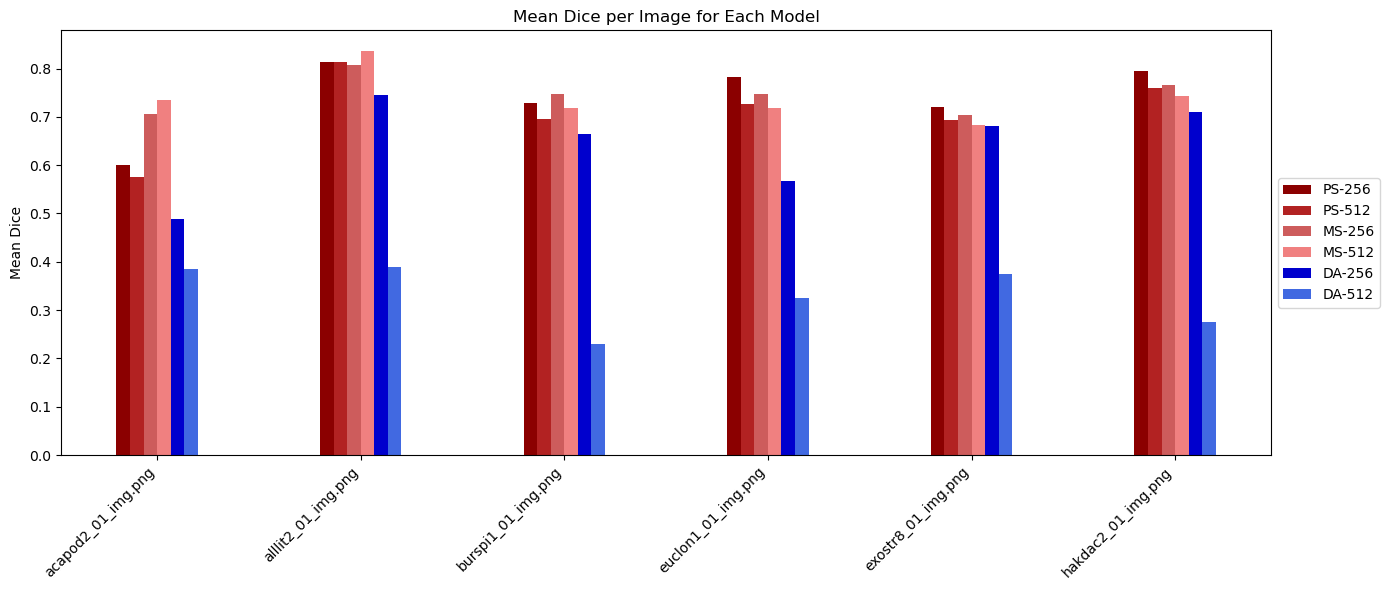

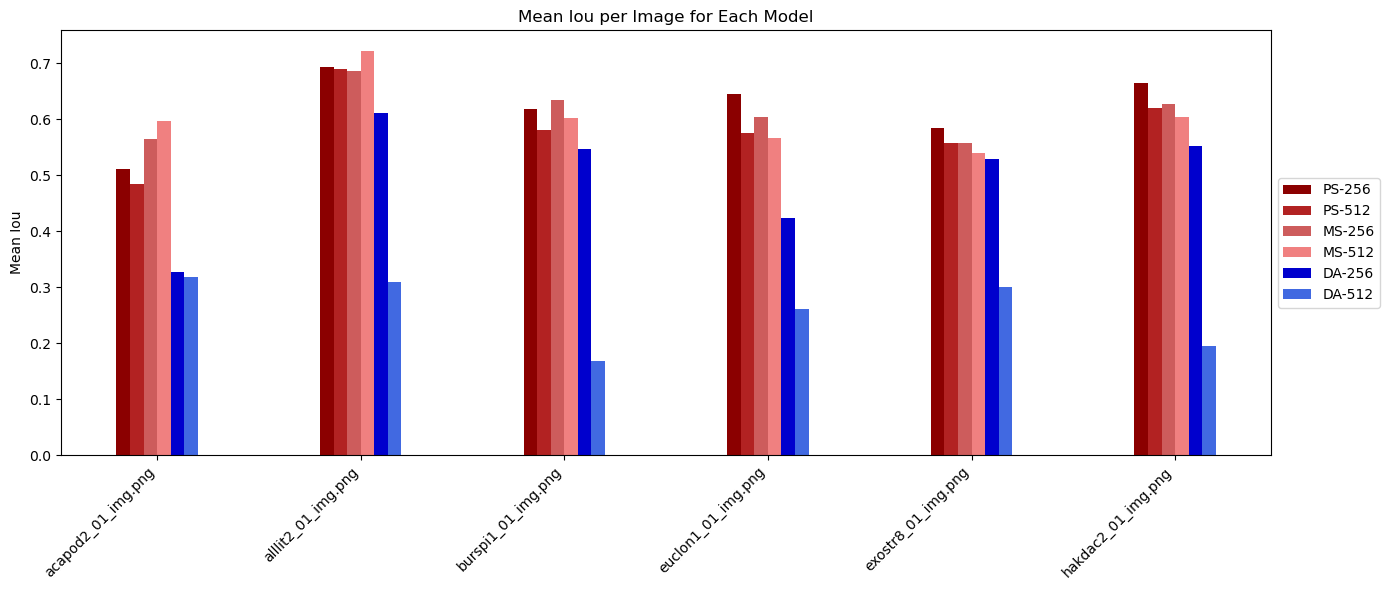

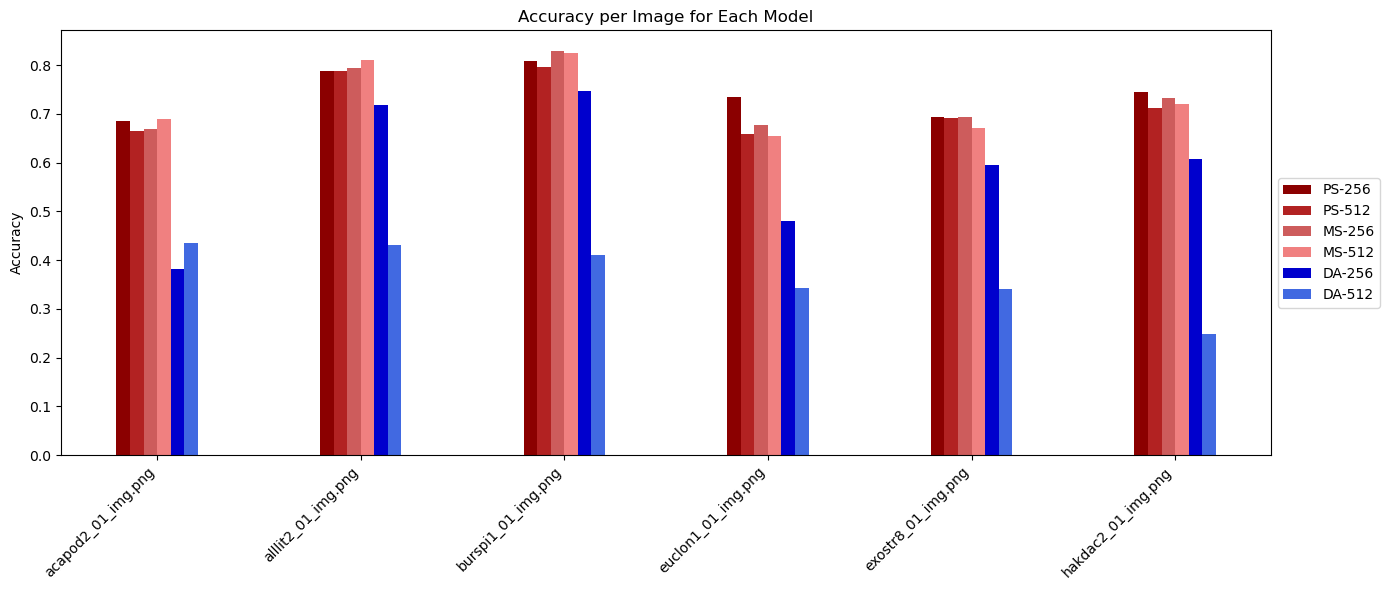

In [13]:
os.makedirs("plots_dfs_without_clearborder", exist_ok=True)

plot_model_scores(metric_name='mean_dice')     # 平均Dice
plot_model_scores(metric_name='mean_iou')      # 平均IoU
plot_model_scores(metric_name='accuracy')      # Accuracy


In [14]:

# === 同じ辞書で3つの指標をループ処理 ===
metrics = ['mean_dice', 'mean_iou', 'accuracy']

for metric_name in metrics:
    results_df = pd.DataFrame(index=species_to_image.values())

    for model_name, path_fn in models.items():
        model_scores = []
        for species, img in species_to_image.items():
            path = path_fn(species, img)
            if os.path.exists(path):
                df = pd.read_csv(path)
                if "multisp" in model_name:
                    df_target = df[df["filename"] == img.replace(".png", "")]
                    value = df_target[metric_name].values[0] if not df_target.empty and metric_name in df_target.columns else None
                else:
                    value = df[metric_name].iloc[0] if metric_name in df.columns else None
            else:
                print(f"[ERROR] File not found: {path}")
                value = None
            model_scores.append(value)

        results_df[model_name] = model_scores

    # CSVで保存
    csv_path = f"plots_dfs_without_clearborder/{metric_name}_table.csv"
    results_df.to_csv(csv_path)
    print(f"[INFO] Saved: {csv_path}")


[INFO] Saved: plots_dfs_without_clearborder/mean_dice_table.csv
[INFO] Saved: plots_dfs_without_clearborder/mean_iou_table.csv
[INFO] Saved: plots_dfs_without_clearborder/accuracy_table.csv


# narrowだけ

In [25]:
import matplotlib as mpl
def plot_model_scores(metric_name='mean_dice'):

    # === color setting ===
    colors = [
        'lightcoral',
        'firebrick',
        'lightskyblue',
        'steelblue',
        'khaki',
        'goldenrod'
    ]
    # === load scores ===
   
    all_scores = {}
    for species, img_name in species_to_image.items():
        scores = []
        for label, path_fn in models.items():
            path = path_fn(species, img_name)
            if os.path.exists(path):
                df = pd.read_csv(path)
                
                # DAまたはMSモデルはfilenameで絞り込む
                if "DA" in label or "MS" in label:
                    df_target = df[df["filename"] == img_name.replace(".png", "")]
                    if not df_target.empty and metric_name in df_target.columns:
                        scores.append(df_target[metric_name].values[0])
                    else:
                        print(f"[WARN] {img_name} の {metric_name} が {label} に見つかりません")
                        scores.append(None)
                else:
                    # PSモデルは1行しかないcsvを前提
                    if metric_name in df.columns:
                        scores.append(df[metric_name].iloc[0])
                    else:
                        print(f"[WARN] {metric_name} が {path} に存在しません")
                        scores.append(None)
            else:
                print(f"[ERROR] ファイルが見つかりません: {path}")
                scores.append(None)
        all_scores[img_name] = scores

    # === モデルごとの平均を計算 ===
    model_labels = list(models.keys())
    num_models = len(model_labels)
    
    # 各モデルの平均スコアを計算（Noneを除外）
    model_averages = []
    for i in range(num_models):
        valid_scores = [all_scores[img][i] for img in all_scores if all_scores[img][i] is not None]
        model_averages.append(np.mean(valid_scores) if valid_scores else None)
  
    # === Visualisation ===
    model_labels = list(models.keys())
    num_models = len(model_labels)
    # === Visualisation ===
    x = [i * 1.15 for i in range(len(all_scores))]
    
    x_avg = max(x) + 2

    custom_labels = ["Acacia", "Allocasuarina", "Bursaria", "Eucalyptus", "Exocarpos", "Hakea", "Model Average"]

    width = 0.12
    fig, ax = plt.subplots(figsize=(14, 6))
    
    for i, (label, color) in enumerate(zip(model_labels, colors)):
        offset = (i - num_models / 2) * width + width / 2
    
        # 通常のバー
        model_scores = [all_scores[img][i] for img in all_scores]
        ax.bar([xi + offset for xi in x], model_scores, width, color=color, label=label)
    
        # 平均バー（右端）
        if model_averages[i] is not None:
            ax.bar(x_avg + offset, model_averages[i], width, color=color)

    ax.set_xticks(x + [x_avg])
    ax.set_xticklabels(custom_labels, rotation=45, ha="right")
    ax.set_ylabel(metric_name.replace('_', ' ').title())
    ax.set_title(f"{metric_name.replace('_', ' ').title()} per Image for Each Model")
    mpl.rcParams['pdf.fonttype'] = 42    
    ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout()
    
    os.makedirs("plots_dfs_without_clearborder", exist_ok=True)
    
    # === CSVとして保存 ===
    df_scores = pd.DataFrame.from_dict(
        all_scores, orient='index', columns=model_labels
    )
    df_scores.index.name = "Image"
    
    # 平均スコアを追加
    df_avg = pd.DataFrame(
        [model_averages], index=["Species Average"], columns=model_labels
    )
    df_all = pd.concat([df_scores, df_avg])

    # 保存
    df_all.to_csv(f"plots_dfs_without_clearborder/{metric_name}_scores.csv")


    plt.savefig(f"plots_dfs_without_clearborder/{metric_name}.pdf", bbox_inches='tight')
    plt.show()


In [16]:
import numpy as np

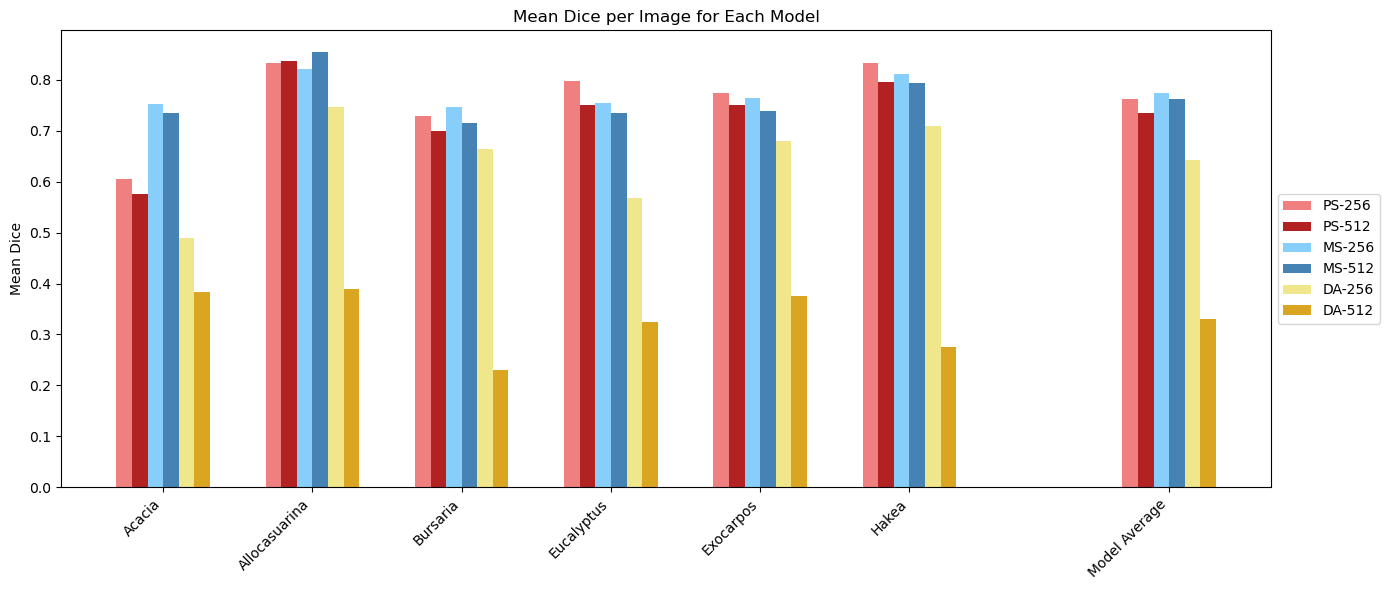

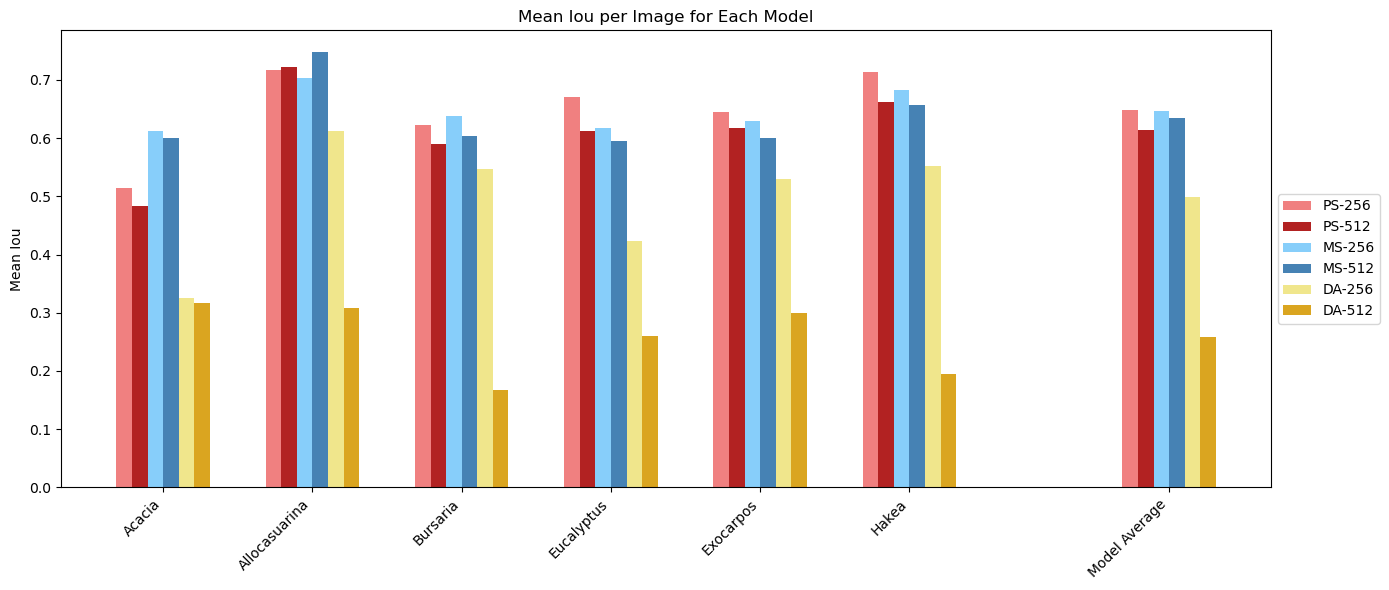

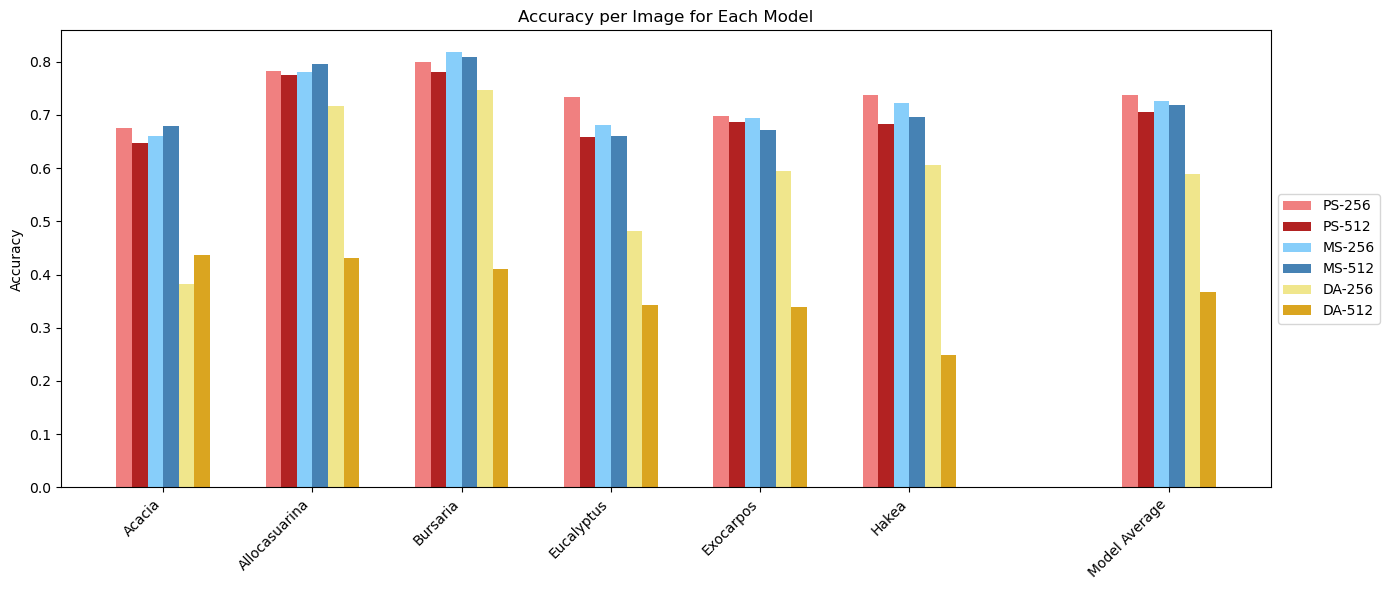

In [26]:
os.makedirs("plots_dfs_without_clearborder", exist_ok=True)

plot_model_scores(metric_name='mean_dice')     # 平均Dice
plot_model_scores(metric_name='mean_iou')      # 平均IoU
plot_model_scores(metric_name='accuracy')      # Accuracy


# Per-class scores

In [19]:


import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_heatmap_per_image(models, species_to_image, score_type="dice", class_order=None):

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, (sp, img_name) in enumerate(species_to_image.items()):
        records = []
        for model_label, path_fn in models.items():
            path = path_fn(sp, img_name)
            if os.path.exists(path):
                df = pd.read_csv(path)
    
                img_base = img_name.replace(".png", "")
                if "filename" in df.columns:
                    df_target = df[df["filename"] == img_base]
                    if df_target.empty:
                        print(f"[WARN] No matching row for {img_base} found in {model_label}")
                        continue
                    row = df_target.iloc[0]
                else:
                    row = df.iloc[0]
    
                for col in df.columns:
                    if col.endswith(f"_{score_type}") and not col.startswith("mean_"):
                        cls = col.replace(f"_{score_type}", "")
                        if cls:
                            score = row[col]
                            records.append({
                                "Class": cls,
                                "Model": model_label,
                                "Score": score
                            })
            else:
                print(f"[ERROR] file not found: {path}")
                
        df_plot = pd.DataFrame(records)
        if df_plot.empty:
            print(f"No valid data found for {img_name}")
            continue

        model_order = ['PS-256', 'PS-512', 'MS-256', 'MS-512', 'DA-256', 'DA-512']
        df_plot["Model"] = pd.Categorical(df_plot["Model"], categories=model_order, ordered=True)

        if class_order:
            df_plot["Class"] = pd.Categorical(df_plot["Class"], categories=class_order, ordered=True)
        df_pivot = df_plot.pivot(index="Class", columns="Model", values="Score")

        sns.heatmap(df_pivot, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1,
                    ax=axes[idx], cbar=False)
        axes[idx].set_title(f"{img_name} - {score_type.upper()}")

    # Hide empty axes (when the number of images is less than 6)
    for j in range(idx + 1, len(axes)):
        axes[j].axis('off')

    fig.suptitle(f"{score_type.upper()} Score per Class for Each Image", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()




In [28]:
species_to_subtitle = {
    "acapod": "Acacia",
    "alllit": "Allocasuarina",
    "burspi": "Bursaria",
    "euclon": "Eucalyptus",
    "exostr": "Exocarpos",
    "hakdac": "Hakea"
}

class_labels = {
    "vessel": "Vessel",
    "fiber": "Fibre",
    "parenchyma": "Axial P",
    "ray": "Ray P"
}

model_labels = {
    "PS-256": "PS-256",
    "PS-512": "PS-512",
    "MS-256": "MS-256",
    "MS-512": "MS-512",
    "DA-256": "DA-256",
    "DA-512": "DA-512"
}

def plot_heatmap_per_image_custom(
    models,
    species_to_image,
    score_type="dice",
    class_order=None,
    class_labels = class_labels,
    model_labels = model_labels,
    title_prefix=None   # e.g. "Per-Class DICE Score"
):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, (sp, img_name) in enumerate(species_to_image.items()):
        records = []
        for model_label, path_fn in models.items():
            path = path_fn(sp, img_name)
            if os.path.exists(path):
                df = pd.read_csv(path)
    
                img_base = img_name.replace(".png", "")
                if "filename" in df.columns:
                    df_target = df[df["filename"] == img_base]
                    if df_target.empty:
                        print(f"[WARN] {img_base} に対応する行が {model_label} に見つかりません")
                        continue
                    row = df_target.iloc[0]
                else:
                    row = df.iloc[0]
    
                for col in df.columns:
                    if col.endswith(f"_{score_type}") and not col.startswith("mean_"):
                        cls = col.replace(f"_{score_type}", "")
                        if cls:
                            score = row[col]
                            records.append({
                                "Class": cls,
                                "Model": model_label,
                                "Score": score
                            })
            else:
                print(f"[ERROR] file not found: {path}")

        df_plot = pd.DataFrame(records)
        if df_plot.empty:
            print(f"No valid data found for {img_name}")
            continue
        model_order = ['PS-256', 'PS-512', 'MS-256', 'MS-512', 'DA-256', 'DA-512']
        df_plot["Model"] = pd.Categorical(df_plot["Model"], categories=model_order, ordered=True)

        if class_order:
            df_plot["Class"] = pd.Categorical(
                df_plot["Class"].map(class_labels).fillna(df_plot["Class"]),
                categories=[class_labels.get(c, c) for c in class_order],
                ordered=True
            )

        df_plot["Model"] = df_plot["Model"].map(model_labels).fillna(df_plot["Model"])
        df_pivot = df_plot.pivot(index="Class", columns="Model", values="Score")

        sns.heatmap(df_pivot, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1,
                    ax=axes[idx], cbar=False)
        axes[idx].set_title(f"{species_to_subtitle.get(sp, sp)} - {score_type.upper()}")

    for j in range(idx + 1, len(axes)):
        axes[j].axis('off')

    if title_prefix:
        fig.suptitle(f"{title_prefix}", fontsize=16)
    else:
        fig.suptitle(f"{score_type.upper()} Score per Class for Each Image", fontsize=16)



# 保存
    mpl.rcParams['pdf.fonttype'] = 42 
    
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.gcf().savefig("plots_dfs_without_clearborder/per_class_dice_narrow_only.pdf")

    plt.show()
    plt.close()



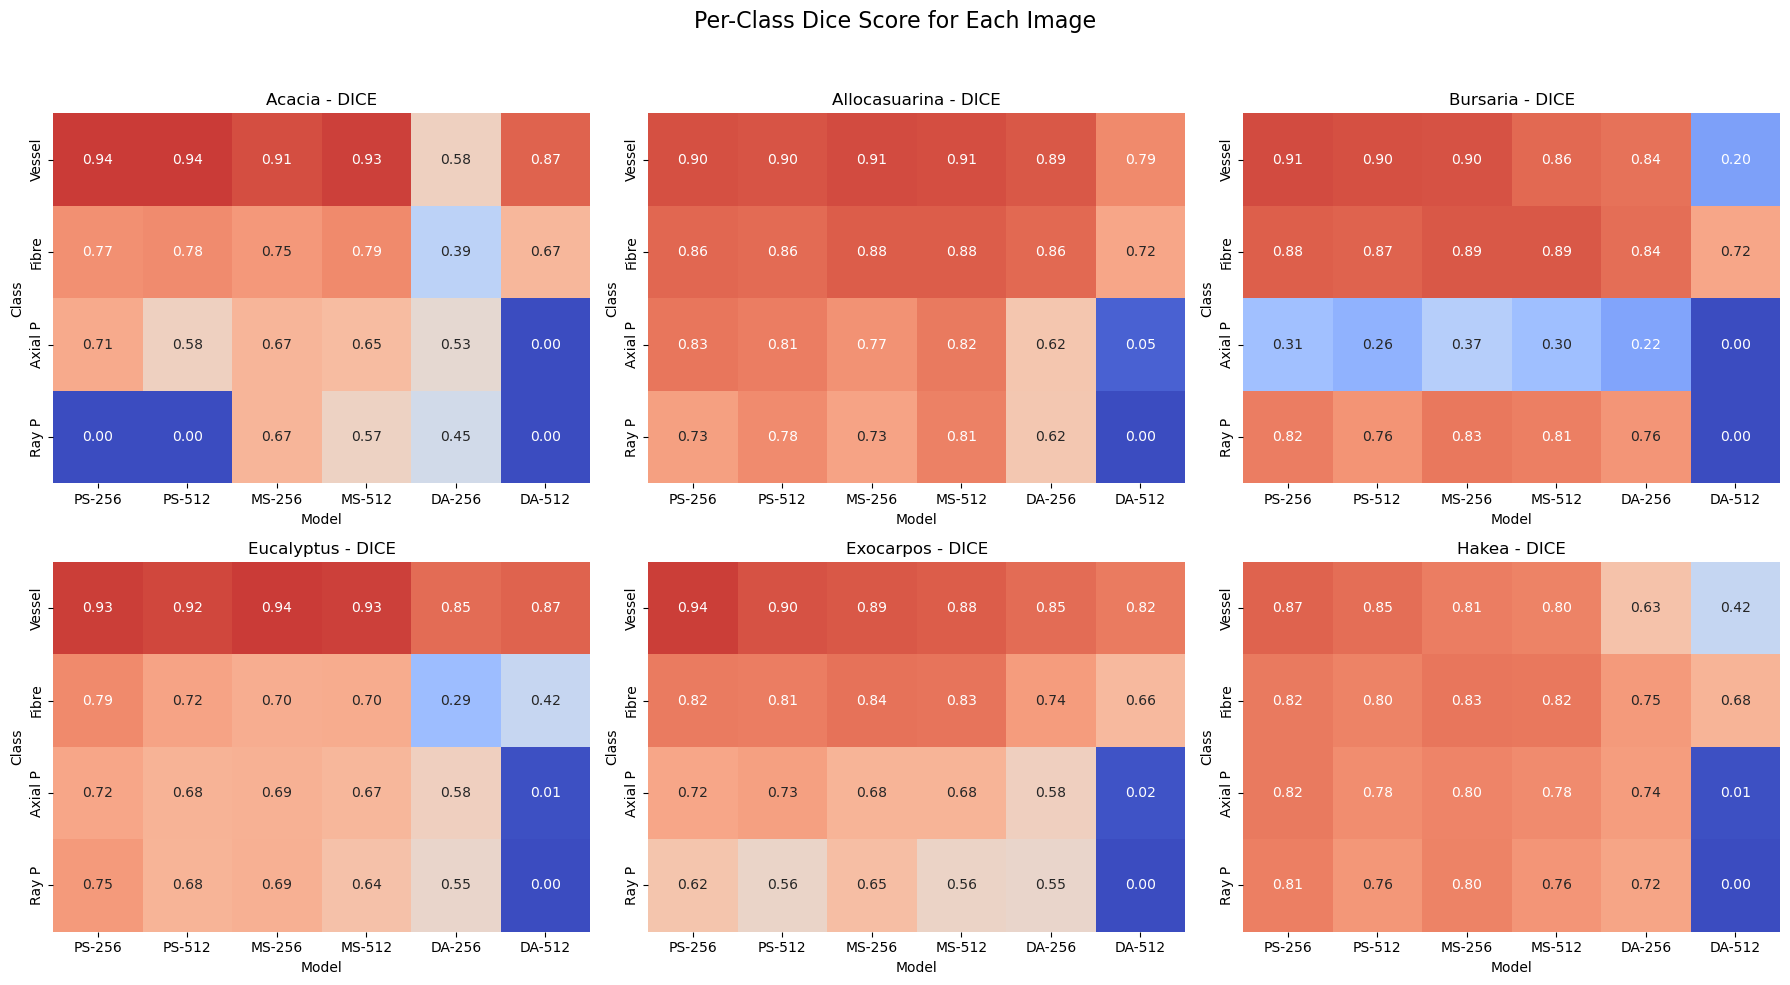

In [29]:

narrow_keys = ["PS-256", "PS-512", "MS-256", "MS-512","DA-256", "DA-512"]
narrow_models = {k: models[k] for k in narrow_keys}
# プロット
plot_heatmap_per_image_custom(
    models=narrow_models,
    species_to_image=species_to_image,
    score_type="dice",
    class_order=["vessel", "fiber", "parenchyma", "ray"],
    class_labels=class_labels,
    model_labels=model_labels,
    title_prefix="Per-Class Dice Score for Each Image"
)


In [22]:
def plot_heatmap_per_image_custom_for_iou(
    models,
    species_to_image,
    score_type="dice",
    class_order=None,
    class_labels = class_labels,
    model_labels = model_labels,
    title_prefix=None   # e.g. "Per-Class DICE Score"
):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, (sp, img_name) in enumerate(species_to_image.items()):
        records = []
        for model_label, path_fn in models.items():
            path = path_fn(sp, img_name)
            if os.path.exists(path):
                df = pd.read_csv(path)
    
                img_base = img_name.replace(".png", "")
                if "filename" in df.columns:
                    df_target = df[df["filename"] == img_base]
                    if df_target.empty:
                        print(f"[WARN] No corresponding entry for {img_base} found in {model_label}")
                        continue
                    row = df_target.iloc[0]
                else:
                    row = df.iloc[0]
    
                for col in df.columns:
                    if col.endswith(f"_{score_type}") and not col.startswith("mean_"):
                        cls = col.replace(f"_{score_type}", "")
                        if cls:
                            score = row[col]
                            records.append({
                                "Class": cls,
                                "Model": model_label,
                                "Score": score
                            })
            else:
                print(f"[ERROR] file not found: {path}")

        df_plot = pd.DataFrame(records)
        if df_plot.empty:
            print(f"No valid data found for {img_name}")
            continue
        model_order = ['PS-256', 'PS-512', 'MS-256', 'MS-512', 'DA-256', 'DA-512']
        df_plot["Model"] = pd.Categorical(df_plot["Model"], categories=model_order, ordered=True)

        if class_order:
            df_plot["Class"] = pd.Categorical(
                df_plot["Class"].map(class_labels).fillna(df_plot["Class"]),
                categories=[class_labels.get(c, c) for c in class_order],
                ordered=True
            )

        df_plot["Model"] = df_plot["Model"].map(model_labels).fillna(df_plot["Model"])
        df_pivot = df_plot.pivot(index="Class", columns="Model", values="Score")

        sns.heatmap(df_pivot, annot=True, fmt=".2f", cmap="coolwarm", vmin=0, vmax=1,
                    ax=axes[idx], cbar=False)
        axes[idx].set_title(f"{species_to_subtitle.get(sp, sp)} - {score_type.upper()}")

    for j in range(idx + 1, len(axes)):
        axes[j].axis('off')

    if title_prefix:
        fig.suptitle(f"{title_prefix}", fontsize=16)
    else:
        fig.suptitle(f"{score_type.upper()} Score per Class for Each Image", fontsize=16)



# 保存

    
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.gcf().savefig("plots_dfs_without_clearborder/per_class_iou_narrow_only.png", dpi=300)

    plt.show()
    plt.close()


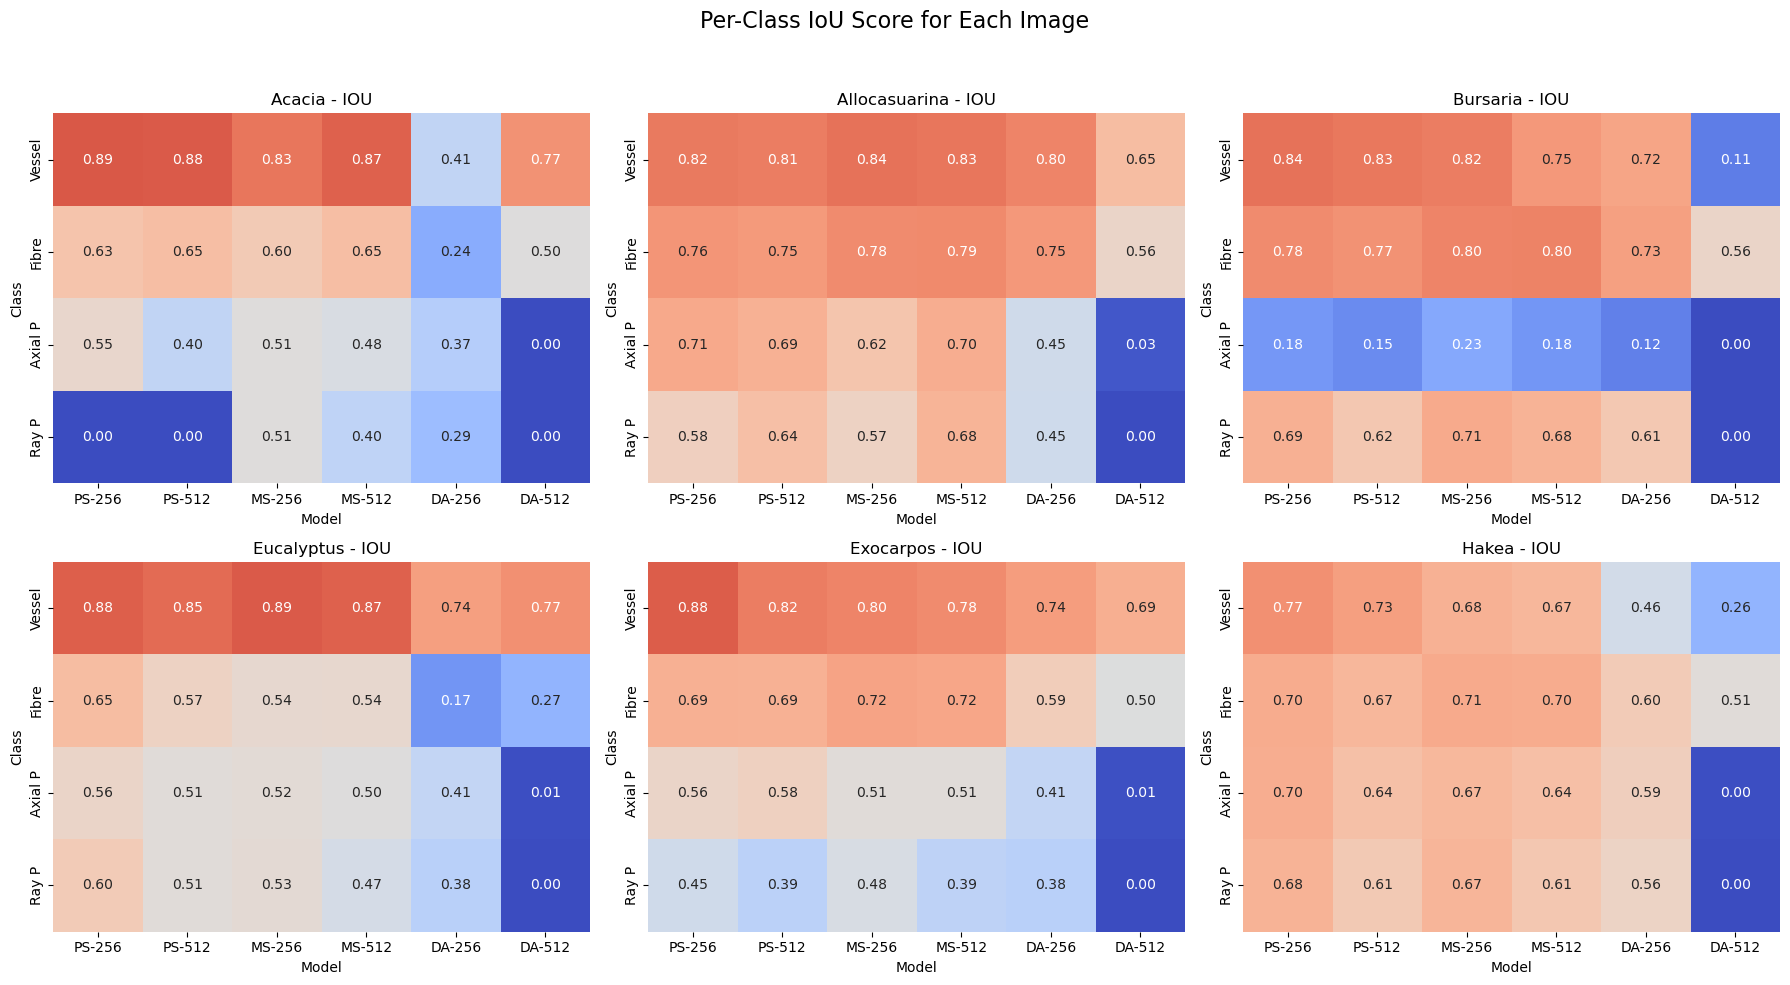

In [23]:

plot_heatmap_per_image_custom_for_iou(
    models=narrow_models,
    species_to_image=species_to_image,
    score_type="iou",
    class_order=["vessel", "fiber", "parenchyma", "ray"],
    class_labels=class_labels,
    model_labels=model_labels,
    title_prefix="Per-Class IoU Score for Each Image"
)